In [1]:
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import ModelCheckpoint
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


In [2]:
tf.__version__

'2.16.2'

In [3]:
keras.__version__

'3.6.0'

In [2]:
fashion_mnist=keras.datasets.fashion_mnist
(X_train_full,y_train_full),(X_test,y_test)=fashion_mnist.load_data()

In [5]:
X_train_full.shape

(60000, 28, 28)

In [6]:
X_train_full.dtype

dtype('uint8')

In [3]:
class_names=["T-shirt/top","Trouser","Pullover","Dress","Coat","Sandal"
             ,"Shirt","Sneaker","Bag","Ankle boot"]

In [9]:
class_names[y_train[0]]

'Coat'

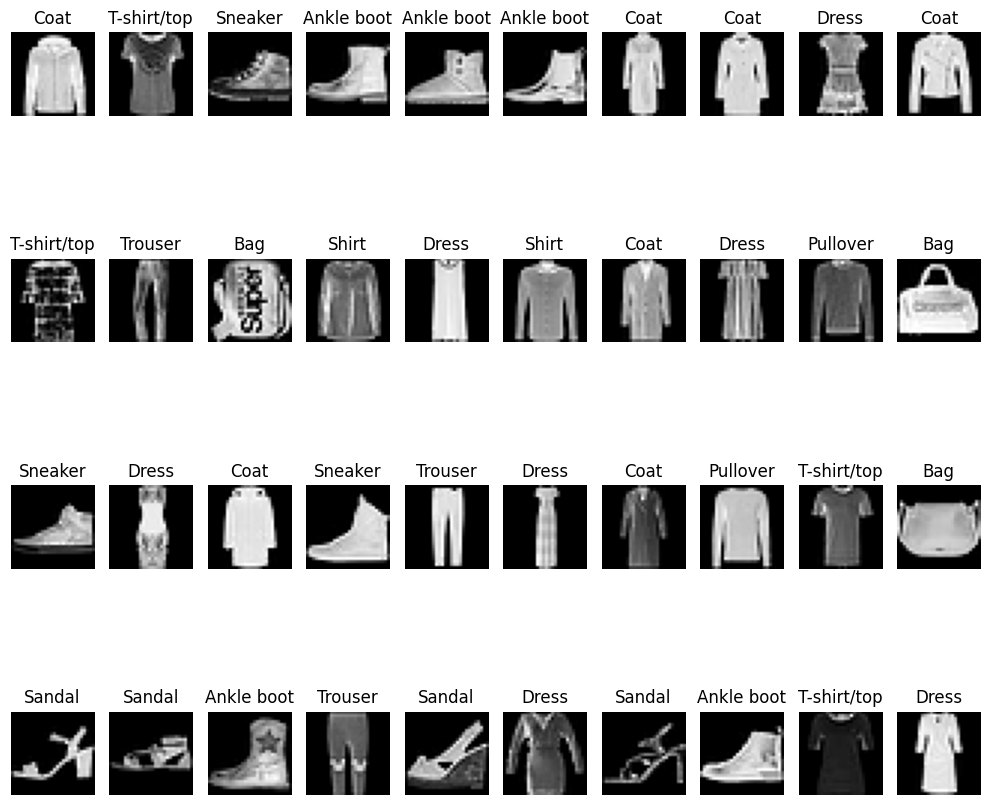

In [10]:
plt.figure(figsize=(10, 10))

# Display a 3x3 grid of images
for i in range(40):
    plt.subplot(4, 10, i + 1)
    plt.imshow(X_train[i], cmap='gray')  # Show images in grayscale
    plt.title(class_names[y_train[i]])  # Display class name
    plt.axis('off')  # Hide axes

plt.tight_layout()
plt.show()

In [11]:

# Define the checkpoint callback
checkpoint_callback = ModelCheckpoint(
    filepath='model_checkpoint.keras',     # Path to save the model file
    save_best_only=True,                # Only save the model with the best validation accuracy
    monitor='val_accuracy',             # Monitor validation accuracy for improvements
    mode='max',                         # Mode for maximizing accuracy
    verbose=1                           # Print updates when model is saved
)



In [4]:
X_valid, X_train = X_train_full[:5000] / 255.0, X_train_full[5000:] / 255.0
y_valid, y_train = y_train_full[:5000], y_train_full[5000:]
X_test = X_test / 255.0

# Reshape data for Conv2D input
X_train = X_train.reshape(-1, 28, 28, 1)
X_valid = X_valid.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

# Convert labels to categorical (one-hot encoding)
y_train = to_categorical(y_train, 10)
y_valid = to_categorical(y_valid, 10)
y_test = to_categorical(y_test, 10)

In [12]:



# Build the Sequential model
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    MaxPooling2D((2, 2)),
    Dropout(0.25),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Dropout(0.25),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(10, activation='softmax')
])

# Compile the model
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])


# Train the model with the checkpoint callback
history = model.fit(
    X_train, y_train,batch_size=64,
    epochs=15,
    validation_data=(X_valid, y_valid),
    callbacks=[checkpoint_callback]     # Add checkpoint callback to the training
)

/opt/anaconda3/envs/myenv/lib/python3.9/site-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
2024-10-30 21:43:47.043029: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M1 Pro
2024-10-30 21:43:47.043068: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2024-10-30 21:43:47.043074: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.33 GB
2024-10-30 21:43:47.043096: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2024-10-30 21:43:47.043114: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory

Epoch 1/15


2024-10-30 21:43:47.572055: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


860/860 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.6614 - loss: 0.9158
Epoch 1: val_accuracy improved from -inf to 0.85560, saving model to model_checkpoint.keras
860/860 ━━━━━━━━━━━━━━━━━━━━ 20s 22ms/step - accuracy: 0.6615 - loss: 0.9155 - val_accuracy: 0.8556 - val_loss: 0.4074
Epoch 2/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8251 - loss: 0.4776
Epoch 2: val_accuracy improved from 0.85560 to 0.87620, saving model to model_checkpoint.keras
860/860 ━━━━━━━━━━━━━━━━━━━━ 18s 21ms/step - accuracy: 0.8251 - loss: 0.4775 - val_accuracy: 0.8762 - val_loss: 0.3351
Epoch 3/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8550 - loss: 0.4069
Epoch 3: val_accuracy improved from 0.87620 to 0.88220, saving model to model_checkpoint.keras
860/860 ━━━━━━━━━━━━━━━━━━━━ 18s 21ms/step - accuracy: 0.8551 - loss: 0.4068 - val_accuracy: 0.8822 - val_loss: 0.3102
Epoch 4/15
860/860 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8664 - loss: 0.3671
Epoch 4: val_accuracy im

In [5]:
from tensorflow.keras.models import load_model

# Load the model from the saved checkpoint
saved_model = load_model('model_checkpoint.keras')

# Evaluate or use the model for predictions
test_loss, test_accuracy =saved_model.evaluate(X_test, y_test)
print(f'\nTest accuracy: {test_accuracy:.4f}')


2024-10-30 23:28:49.714937: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M1 Pro
2024-10-30 23:28:49.715100: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2024-10-30 23:28:49.715135: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.33 GB
2024-10-30 23:28:49.715266: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2024-10-30 23:28:49.715320: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


  1/313 ━━━━━━━━━━━━━━━━━━━━ 1:26 278ms/step - accuracy: 0.9062 - loss: 0.4035

2024-10-30 23:28:50.198876: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9119 - loss: 0.2482

Test accuracy: 0.9108


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


<Figure size 1000x800 with 0 Axes>

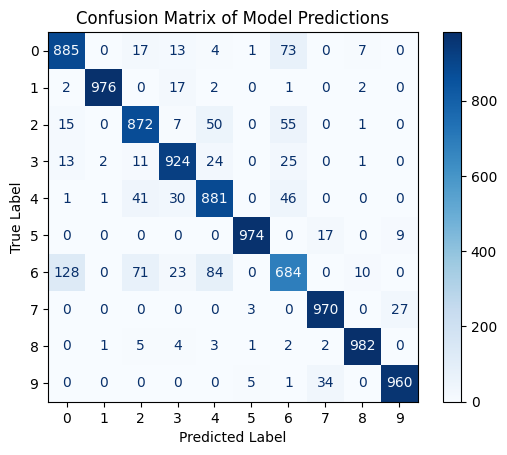

In [19]:

# Step 1: Generate predictions
y_pred = saved_model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = np.argmax(y_test, axis=1)  # Convert one-hot to class indices if necessary

# Step 2: Compute confusion matrix
cm = confusion_matrix(y_true, y_pred_classes)

# Step 3: Plot the confusion matrix
plt.figure(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=range(10))
disp.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix of Model Predictions')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

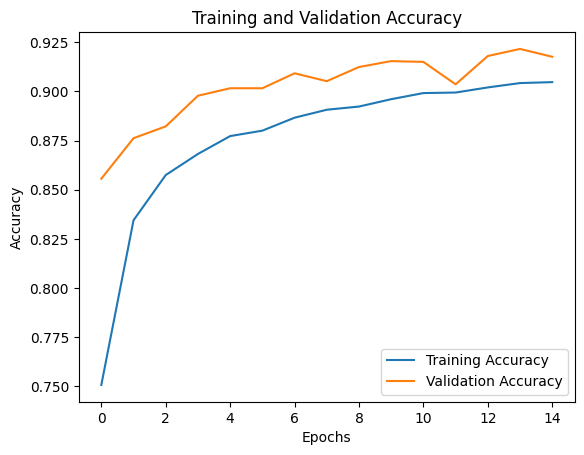

In [20]:
# Plot training & validation accuracy values
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [21]:
!pip install flask tensorflow


In [9]:
X_test[0].shape

(28, 28, 1)

In [11]:
from flask import Flask, request, jsonify
from tensorflow.keras.models import load_model
import numpy as np
import tensorflow as tf

# Initialize the Flask app
app = Flask(__name__)

# Load the pre-trained model
model = load_model("model_checkpoint.keras")

# Define a route for the prediction
@app.route('/predict', methods=['POST'])
def predict():
    # Parse the incoming JSON request for image data
    data = request.get_json()
    if 'image' not in data:
        return jsonify({"error": "No image data found"}), 400

    # Get the image data from the request (expecting it as a 2D list)
    try:
        image_data=X_test[0].reshape(1, 28, 28, 1)  # Reshape as needed
    except ValueError:
        return jsonify({"error": "Invalid image data format"}), 400

    # Make a prediction using the model
    with tf.device("/cpu:0"):  # Explicitly run on CPU if no GPU is available or for compatibility
        prediction = model.predict(image_data)
    
    # Get the class with the highest probability
    predicted_class = np.argmax(prediction[0])
    confidence = float(np.max(prediction[0]))

    # Return the result as JSON
    return jsonify({
        "predicted_class": int(predicted_class),
        "confidence": confidence
    })

# Run the Flask app
if __name__ == "__main__":
    app.run(host="0.0.0.0", port=5003, debug=True)


 * Serving Flask app '__main__'
 * Debug mode: on


 * Running on all addresses (0.0.0.0)
 * Running on http://127.0.0.1:5003
 * Running on http://192.168.1.121:5003
Press CTRL+C to quit
 * Restarting with stat
Traceback (most recent call last):
  File "/opt/anaconda3/envs/myenv/lib/python3.9/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/opt/anaconda3/envs/myenv/lib/python3.9/site-packages/traitlets/config/application.py", line 1074, in launch_instance
    app.initialize(argv)
  File "/opt/anaconda3/envs/myenv/lib/python3.9/site-packages/traitlets/config/application.py", line 118, in inner
    return method(app, *args, **kwargs)
  File "/opt/anaconda3/envs/myenv/lib/python3.9/site-packages/ipykernel/kernelapp.py", line 692, in initialize
    self.init_sockets()
  File "/opt/anaconda3/envs/myenv/lib/python3.9/site-packages/ipykernel/kernelapp.py", line 331, in init_sockets
    self.shell_port = self._bind_socket(self.shell_socket, self.shell_port)
  File "/opt/anaconda3/envs/myenv/lib/p

SystemExit: 1

/opt/anaconda3/envs/myenv/lib/python3.9/site-packages/IPython/core/interactiveshell.py:3534: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [12]:
if __name__ == '__main__':
    app.run(host='0.0.0.0', port=5005)

 * Serving Flask app '__main__'
 * Debug mode: on


 * Running on all addresses (0.0.0.0)
 * Running on http://127.0.0.1:5005
 * Running on http://192.168.1.121:5005
Press CTRL+C to quit
 * Restarting with stat
Traceback (most recent call last):
  File "/opt/anaconda3/envs/myenv/lib/python3.9/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/opt/anaconda3/envs/myenv/lib/python3.9/site-packages/traitlets/config/application.py", line 1074, in launch_instance
    app.initialize(argv)
  File "/opt/anaconda3/envs/myenv/lib/python3.9/site-packages/traitlets/config/application.py", line 118, in inner
    return method(app, *args, **kwargs)
  File "/opt/anaconda3/envs/myenv/lib/python3.9/site-packages/ipykernel/kernelapp.py", line 692, in initialize
    self.init_sockets()
  File "/opt/anaconda3/envs/myenv/lib/python3.9/site-packages/ipykernel/kernelapp.py", line 331, in init_sockets
    self.shell_port = self._bind_socket(self.shell_socket, self.shell_port)
  File "/opt/anaconda3/envs/myenv/lib/p

SystemExit: 1

In [13]:
from flask import Flask

app = Flask(__name__)

@app.route('/')
def hello():
    return "Hello, World!"

if __name__ == '__main__':
    app.run(port=5000)  # You can specify the port here

 * Serving Flask app '__main__'
 * Debug mode: off


 * Running on http://127.0.0.1:5000
Press CTRL+C to quit


In [7]:
import threading

def run_app():
    app.run(port=5000)

thread = threading.Thread(target=run_app)
thread.start()

 * Serving Flask app '__main__'
 * Debug mode: off


 * Running on http://127.0.0.1:5000
Press CTRL+C to quit


In [8]:
x_test[0]

NameError: name 'x_test' is not defined

In [ ]:
from flask import Flask, request, jsonify
from tensorflow.keras.models import load_model
import numpy as np
import tensorflow as tf

# Initialize the Flask app
app = Flask(__name__)

# Load the pre-trained model
model = load_model("model_checkpoint.keras")

# Load or define your test set here
# For example, assume test_images is a NumPy array of shape (num_samples, 28, 28, 1)
test_images = x_test[0]  # Load your test images here

# Define a route for the prediction
@app.route('/predict', methods=['POST'])
def predict():
    # Parse the incoming JSON request for the instance index
    data = request.get_json()
    if 'index' not in data:
        return jsonify({"error": "No index found"}), 400

    index = data['index']
    
    # Ensure the index is valid
    if index < 0 or index >= len(test_images):
        return jsonify({"error": "Index out of bounds"}), 400

    # Get the image data for the given index
    image_data = test_images[index].reshape(1, 28, 28, 1)  # Reshape as needed

    # Make a prediction using the model
    with tf.device("/cpu:0"):  # Explicitly run on CPU if no GPU is available or for compatibility
        prediction = model.predict(image_data)

    # Get the class with the highest probability
    predicted_class = np.argmax(prediction[0])
    confidence = float(np.max(prediction[0]))

    # Return the result as JSON
    return jsonify({
        "predicted_class": int(predicted_class),
        "confidence": confidence
    })

# Run the Flask app
if __name__ == "__main__":
    app.run(host="0.0.0.0", port=5001, debug=True)


In [6]:
import os
import signal
import subprocess

def kill_process_on_port(port):
    try:
        # Get the list of all processes using the specified port
        result = subprocess.check_output(["lsof", "-t", f"-i:{port}"])
        pids = result.decode().strip().split("\n")

        for pid in pids:
            os.kill(int(pid), signal.SIGKILL)  # Forcefully kill the process
        print(f"Killed processes on port {port}: {', '.join(pids)}")
    except subprocess.CalledProcessError:
        print(f"No process found on port {port}.")

# Specify the port number you want to free up
PORT = 5003
kill_process_on_port(PORT)

# Rest of your Flask app code follows...


No process found on port 5003.


In [7]:
from flask import Flask, request, jsonify
from tensorflow.keras.models import load_model
import numpy as np
import tensorflow as tf
import os
import signal
import subprocess

# Function to kill processes on a specific port
def kill_process_on_port(port):
    try:
        # Get the list of all processes using the specified port
        result = subprocess.check_output(["lsof", "-t", f"-i:{port}"])
        pids = result.decode().strip().split("\n")

        for pid in pids:
            os.kill(int(pid), signal.SIGKILL)  # Forcefully kill the process
        print(f"Killed processes on port {port}: {', '.join(pids)}")
    except subprocess.CalledProcessError:
        print(f"No process found on port {port}.")

# Initialize the Flask app
app = Flask(__name__)

# Load the pre-trained model
model = load_model("model_checkpoint.keras")

# Specify the port number you want to use
PORT = 5003
kill_process_on_port(PORT)

# Define a route for the prediction
@app.route('/predict', methods=['POST'])
def predict():
    # Parse the incoming JSON request for image data
    data = request.get_json()
    if 'image' not in data:
        return jsonify({"error": "No image data found"}), 400

    # Get the image data from the request (expecting it as a 2D list)
    try:
        image_data = X_test[0].reshape(1, 28, 28, 1)  # Reshape as needed
    except ValueError:
        return jsonify({"error": "Invalid image data format"}), 400

    # Make a prediction using the model
    with tf.device("/cpu:0"):  # Explicitly run on CPU if no GPU is available or for compatibility
        prediction = model.predict(image_data)
    
    # Get the class with the highest probability
    predicted_class = np.argmax(prediction[0])
    confidence = float(np.max(prediction[0]))

    # Return the result as JSON
    return jsonify({
        "predicted_class": int(predicted_class),
        "confidence": confidence
    })

# Run the Flask app
if __name__ == "__main__":
    app.run(host="0.0.0.0", port=PORT, debug=True)


No process found on port 5003.
 * Serving Flask app '__main__'
 * Debug mode: on


 * Running on all addresses (0.0.0.0)
 * Running on http://127.0.0.1:5003
 * Running on http://192.168.1.121:5003
Press CTRL+C to quit
 * Restarting with stat
Traceback (most recent call last):
  File "/opt/anaconda3/envs/myenv/lib/python3.9/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/opt/anaconda3/envs/myenv/lib/python3.9/site-packages/traitlets/config/application.py", line 1074, in launch_instance
    app.initialize(argv)
  File "/opt/anaconda3/envs/myenv/lib/python3.9/site-packages/traitlets/config/application.py", line 118, in inner
    return method(app, *args, **kwargs)
  File "/opt/anaconda3/envs/myenv/lib/python3.9/site-packages/ipykernel/kernelapp.py", line 692, in initialize
    self.init_sockets()
  File "/opt/anaconda3/envs/myenv/lib/python3.9/site-packages/ipykernel/kernelapp.py", line 331, in init_sockets
    self.shell_port = self._bind_socket(self.shell_socket, self.shell_port)
  File "/opt/anaconda3/envs/myenv/lib/p

SystemExit: 1

/opt/anaconda3/envs/myenv/lib/python3.9/site-packages/IPython/core/interactiveshell.py:3534: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [6]:
from flask import Flask, request, jsonify
from tensorflow.keras.models import load_model
import numpy as np
import tensorflow as tf
import os
import signal
import subprocess
import threading

# Function to kill processes on a specific port
def kill_process_on_port(port):
    try:
        # Get the list of all processes using the specified port
        result = subprocess.check_output(["lsof", "-t", f"-i:{port}"])
        pids = result.decode().strip().split("\n")

        for pid in pids:
            os.kill(int(pid), signal.SIGKILL)  # Forcefully kill the process
        print(f"Killed processes on port {port}: {', '.join(pids)}")
    except subprocess.CalledProcessError:
        print(f"No process found on port {port}.")

# Initialize the Flask app
app = Flask(__name__)

# Load the pre-trained model
model = load_model("model_checkpoint.keras")

# Specify the port number you want to use
PORT = 5003
kill_process_on_port(PORT)

# Define a route for the prediction
@app.route('/predict', methods=['POST'])
def predict():
    # Parse the incoming JSON request for image data
    data = request.get_json()
    if 'image' not in data:
        return jsonify({"error": "No image data found"}), 400

    # Get the image data from the request (expecting it as a 2D list)
    try:
        image_data = X_test[0].reshape(1, 28, 28, 1)  # Reshape as needed
    except ValueError:
        return jsonify({"error": "Invalid image data format"}), 400

    # Make a prediction using the model
    with tf.device("/cpu:0"):  # Explicitly run on CPU if no GPU is available or for compatibility
        prediction = model.predict(image_data)
    
    # Get the class with the highest probability
    predicted_class = np.argmax(prediction[0])
    confidence = float(np.max(prediction[0]))

    # Return the result as JSON
    return jsonify({
        "predicted_class": int(predicted_class),
        "confidence": confidence
    })

# Function to run the Flask app
def run_app():
    app.run(host="0.0.0.0", port=PORT, debug=True, use_reloader=False)  # Set use_reloader to False

# Run the Flask app in a separate thread
threading.Thread(target=run_app).start()


No process found on port 5003.
 * Serving Flask app '__main__'
 * Debug mode: on


 * Running on all addresses (0.0.0.0)
 * Running on http://127.0.0.1:5003
 * Running on http://192.168.1.121:5003
Press CTRL+C to quit


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step


127.0.0.1 - - [30/Oct/2024 23:32:44] "POST /predict HTTP/1.1" 200 -


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step


127.0.0.1 - - [30/Oct/2024 23:38:45] "POST /predict HTTP/1.1" 200 -


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step


127.0.0.1 - - [30/Oct/2024 23:46:55] "POST /predict HTTP/1.1" 200 -
127.0.0.1 - - [30/Oct/2024 23:50:39] "GET /predict HTTP/1.1" 405 -
127.0.0.1 - - [30/Oct/2024 23:50:48] "GET /predict HTTP/1.1" 405 -
127.0.0.1 - - [30/Oct/2024 23:50:48] "GET /favicon.ico HTTP/1.1" 404 -
127.0.0.1 - - [30/Oct/2024 23:52:01] "POST /predict HTTP/1.1" 400 -
127.0.0.1 - - [30/Oct/2024 23:52:54] "POST /predict HTTP/1.1" 400 -
127.0.0.1 - - [30/Oct/2024 23:54:25] "POST /predict HTTP/1.1" 400 -
127.0.0.1 - - [30/Oct/2024 23:54:50] "POST /predict HTTP/1.1" 400 -
127.0.0.1 - - [30/Oct/2024 23:56:19] "POST /predict HTTP/1.1" 400 -
127.0.0.1 - - [31/Oct/2024 00:01:40] "POST /predict HTTP/1.1" 400 -


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step


127.0.0.1 - - [31/Oct/2024 00:03:30] "POST /predict HTTP/1.1" 200 -


In [13]:
import requests
import numpy as np

# Sample image data to send (reshape it according to your model's input requirements)
# Here we create a dummy image as a 28x28 array filled with zeros (or you can use actual image data)
dummy_image = np.zeros((28, 28)).tolist()  # Convert to list for JSON serialization

# Define the URL of your Flask app
url = 'http://127.0.0.1:5003/predict'

# Prepare the JSON payload
data = {
    "image": [
    [[0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.]],
    [[0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.]],
    [[0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.]],
    [[0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.]],
    [[0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.]],
    [[0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.]],
    [[0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.]],
    [[0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.01176471], [0.00392157], [0.], [0.], [0.02745098], [0.], [0.14509804], [0.], [0.]],
    [[0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.00392157], [0.00784314], [0.], [0.10588235], [0.32941176], [0.04313725], [0.], [0.], [0.], [0.], [0.], [0.], [0.46666667], [0.], [0.]],
    [[0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.00392157], [0.], [0.], [0.34509804], [0.56078431], [0.43137255], [0.], [0.], [0.], [0.], [0.08627451], [0.36470588], [0.41568627], [0.], [0.]],
    [[0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.01568627], [0.], [0.20784314], [0.50588235], [0.47058824], [0.57647059], [0.68627451], [0.61568627], [0.65098039], [0.52941176], [0.60392157], [0.65882353], [0.54901961], [0.], [0.]],
    [[0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.00784314], [0.], [0.04313725], [0.5372549], [0.50980392], [0.50196078], [0.62745098], [0.69019608], [0.62352941], [0.65490196], [0.69803922], [0.58431373], [0.59215686], [0.56470588], [0.], [0.]],
    [[0.], [0.], [0.], [0.], [0.], [0.], [0.00392157], [0.], [0.00784314], [0.00392157], [0.], [0.01176471], [0.], [0.], [0.45098039], [0.44705882], [0.41568627], [0.5372549], [0.65882353], [0.6], [0.61176471], [0.64705882], [0.65490196], [0.56078431], [0.61568627], [0.61960784], [0.04313725], [0.]],
    [[0.], [0.], [0.], [0.], [0.00392157], [0.], [0.], [0.], [0.], [0.], [0.01176471], [0.], [0.], [0.34901961], [0.54509804], [0.35294118], [0.36862745], [0.6], [0.58431373], [0.51372549], [0.59215686], [0.6627451], [0.6745098], [0.56078431], [0.62352941], [0.6627451], [0.18823529], [0.]],
    [[0.], [0.], [0.], [0.], [0.], [0.], [0.00784314], [0.01568627], [0.00392157], [0.], [0.], [0.], [0.38431373], [0.53333333], [0.43137255], [0.42745098], [0.43137255], [0.63529412], [0.52941176], [0.56470588], [0.58431373], [0.62352941], [0.65490196], [0.56470588], [0.61960784], [0.6627451], [0.46666667], [0.]],
    [[0.], [0.], [0.00784314], [0.00784314], [0.00392157], [0.00784314], [0.], [0.], [0.], [0.], [0.], [0.], [0.09411765], [0.31372549], [0.41960784], [0.31372549], [0.35686275], [0.37647059], [0.62352941], [0.58039216], [0.56470588], [0.67058824], [0.61960784], [0.61176471], [0.65098039], [0.61960784], [0.], [0.]],
    [[0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.03921569], [0.15686275], [0.4], [0.23921569], [0.38039216], [0.30980392], [0.35294118], [0.5372549], [0.62745098], [0.6], [0.61568627], [0.6], [0.52156863], [0.18039216], [0.]],
    [[0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.35294118], [0.50196078], [0.58823529], [0.61176471], [0.59215686], [0.54117647], [0.54117647], [0.32156863], [0.]],
    [[0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.]],
    [[0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.]],
    [[0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.]],
    [[0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.]],
    [[0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.]],
    [[0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.], [0.]]
  ]

    
}

# Send a POST request
response = requests.post(url, json=data)

# Print the response
print("Status Code:", response.status_code)
print("Response JSON:", response.json())



Status Code: 200
Response JSON: {'confidence': 0.9999514818191528, 'predicted_class': 9}


In [25]:
class_names[response.json()['predicted_class']]

'Ankle boot'

In [3]:
!git config --global user.name "Abdurrahman-Sabbahi"
!git config --global user.email "a.sabbahi90@gmail.com"


In [2]:
%cd /Users/abdurrahmansabbahi/Documents/GitHub/NewRepo


/Users/abdurrahmansabbahi/Documents/GitHub/NewRepo


In [46]:
!mv /Users/abdurrahmansabbahi/Aurelion_HOML/MNIST_Fashion.ipynb /Users/abdurrahmansabbahi/Documents/GitHub/NewRepo


In [3]:
!git add MNIST_Fashion.ipynb

In [12]:
!git commit -m "This is my first commit to the MNIST Fashion project that includes model inferencing"

On branch main
Untracked files:
  (use "git add <file>..." to include in what will be committed)
	.DS_Store

nothing added to commit but untracked files present (use "git add" to track)


In [13]:
!echo .DS_Store >> .gitignore

In [14]:
!git add .gitignore
!git commit -m "Add .DS_Store to .gitignore"

[main d9aaa57] Add .DS_Store to .gitignore
 1 file changed, 1 insertion(+)
 create mode 100644 .gitignore


In [15]:
!git status

On branch main
nothing to commit, working tree clean


In [16]:
!git log --oneline

d9aaa57 (HEAD -> main) Add .DS_Store to .gitignore
36cb88a This is my first commit to the MNIST Fashion project that includes model inferencing


In [ ]:
!git push origin main


In [18]:
Abdurrahman-Sabbahi

NameError: name 'Abdurrahman' is not defined